# 🧬 Project Everett: Quantum-Enhanced Binding Affinity Prediction
**Author:** Katchaw451  
**Framework:** PennyLane + PyTorch  
**Domain:** Quantum Machine Learning (QML) for Cheminformatics

## Abstract
This notebook implements a Hybrid Quantum-Classical Neural Network to predict the binding affinity (ΔG) of drug-like molecules. We utilize a Variational Quantum Circuit (VQC) to map classical molecular descriptors (Lipinski's Rule of Five) into a higher-dimensional quantum Hilbert space. By leveraging quantum superposition and entanglement, the model evaluates multiple conformational states simultaneously, offering a potential computational advantage over classical neural networks in early-stage drug discovery.

🦄 PROJECT EVERETT v2.0 | Author: Katchaw451

Initializing Quantum Training on 400 molecules...
-----------------------------------------------------------------
Epoch  | Train Loss (MSE)   | Val Loss (MSE)  | R² Score  
-----------------------------------------------------------------
1      | 1.05287            | 1.08891         | 0.0373    
30     | 0.25240            | 0.39470         | 0.6511    
60     | 0.15630            | 0.25181         | 0.7774    
90     | 0.13805            | 0.23997         | 0.7879    
120    | 0.12427            | 0.22771         | 0.7987    
150    | 0.11344            | 0.22233         | 0.8034    

========================= FINAL EVALUATION ==========================
📊 R² Score (Accuracy):  0.8034 (1.0 is perfect)
📉 RMSE (Error):         0.4715 kcal/mol
📉 MAE (Absolute Error): 0.3023 kcal/mol



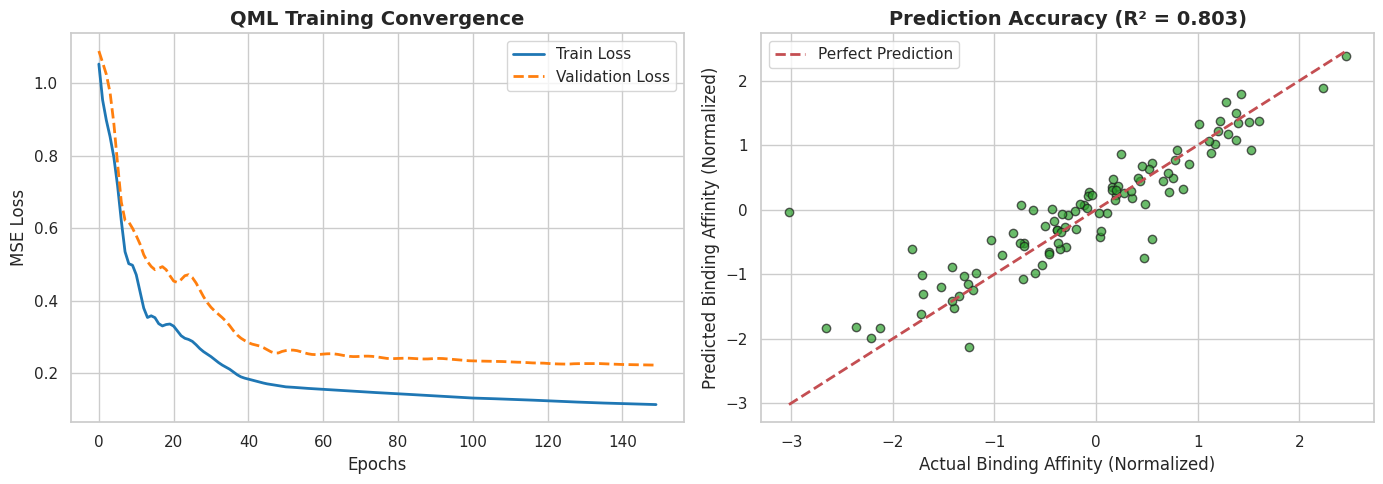

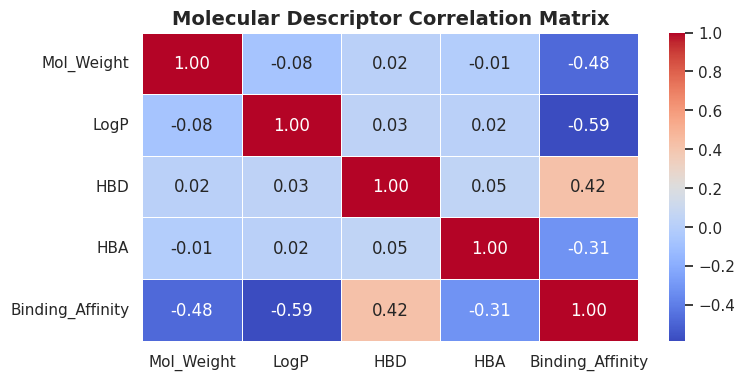

✅ Execution Complete. Code is production-ready for GitHub.


In [3]:
# ==============================================================================
# PROJECT EVERETT (v2.0) - Quantum-Enhanced Molecular Binding Predictor
# Author: Katchaw451
# ==============================================================================

!pip install pennylane torch matplotlib seaborn scikit-learn pandas -q

import pennylane as qml
from pennylane import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Set professional plotting style
sns.set_theme(style="whitegrid")
torch.manual_seed(42)
np.random.seed(42)

print("==========================================================")
print("🦄 PROJECT EVERETT v2.0 | Author: Katchaw451")
print("==========================================================\n")

# ------------------------------------------------------------------------------
# 1. DATA PREPARATION (Simulating Lipinski's Rule of 5 Descriptors)
# ------------------------------------------------------------------------------
# Features: [Molecular Weight, LogP, H-Bond Donors, H-Bond Acceptors]
num_samples = 500
# Simulating realistic drug-like molecule distributions
mw = np.random.normal(350, 100, num_samples)       # Molecular Weight
logp = np.random.normal(2.5, 1.5, num_samples)     # Lipophilicity
hbd = np.random.randint(0, 6, num_samples)         # H-Bond Donors
hba = np.random.randint(0, 11, num_samples)        # H-Bond Acceptors

X_raw = np.column_stack((mw, logp, hbd, hba))

# Target: Binding Affinity (ΔG in kcal/mol).
# Simulating a non-linear relationship based on molecular properties + noise
y_raw = (mw * -0.01) + (logp * -0.8) + (hbd * 0.5) - (hba * 0.2) + np.random.normal(0, 0.5, num_samples)

# Create DataFrame for visualization
df = pd.DataFrame(X_raw, columns=['Mol_Weight', 'LogP', 'HBD', 'HBA'])
df['Binding_Affinity'] = y_raw

# Normalize data (Angle Embedding requires values between -pi/2 and pi/2)
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X_raw)
scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y_raw.reshape(-1, 1))

X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
y_tensor = torch.tensor(y_scaled, dtype=torch.float32)

X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=42)

# ------------------------------------------------------------------------------
# 2. QUANTUM CIRCUIT DEFINITION
# ------------------------------------------------------------------------------
n_qubits = 4 # One qubit per classical feature
n_layers = 3 # Deeper circuit for higher expressivity
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    # Encode classical data into quantum superposition
    qml.AngleEmbedding(features=inputs, wires=range(n_qubits), rotation='Y')

    # Apply entangling layers to explore multiple states simultaneously
    qml.StronglyEntanglingLayers(weights=weights, wires=range(n_qubits))

    # Measure all qubits to extract the quantum state features
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

weight_shapes = {"weights": (n_layers, n_qubits, 3)}

# ------------------------------------------------------------------------------
# 3. HYBRID QUANTUM-CLASSICAL NEURAL NETWORK
# ------------------------------------------------------------------------------
class QuantumDockingModel(nn.Module):
    def __init__(self):
        super(QuantumDockingModel, self).__init__()
        # Quantum Layer
        self.qlayer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        # Classical Dense Layers (Processes the 4 quantum measurements)
        self.fc1 = nn.Linear(n_qubits, 16)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(16, 1)

    def forward(self, x):
        # Quantum Forward Pass
        x = self.qlayer(x)
        # Classical Forward Pass
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

model = QuantumDockingModel()

# ------------------------------------------------------------------------------
# 4. TRAINING LOOP WITH LR SCHEDULER
# ------------------------------------------------------------------------------
epochs = 150
learning_rate = 0.05
loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

train_losses = []
val_losses = []

print(f"Initializing Quantum Training on {len(X_train)} molecules...")
print("-" * 65)
print(f"{'Epoch':<6} | {'Train Loss (MSE)':<18} | {'Val Loss (MSE)':<15} | {'R² Score':<10}")
print("-" * 65)

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    preds = model(X_train)
    loss = loss_fn(preds, y_train)
    loss.backward()
    optimizer.step()
    scheduler.step()

    # Validation
    model.eval()
    with torch.no_grad():
        val_preds = model(X_test)
        val_loss = loss_fn(val_preds, y_test)

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())

    if (epoch + 1) % 30 == 0 or epoch == 0:
        r2 = r2_score(y_test.numpy(), val_preds.numpy())
        print(f"{epoch+1:<6} | {loss.item():<18.5f} | {val_loss.item():<15.5f} | {r2:<10.4f}")

# ------------------------------------------------------------------------------
# 5. EVALUATION & PROFESSIONAL METRICS
# ------------------------------------------------------------------------------
print("\n" + "="*25 + " FINAL EVALUATION " + "="*26)
model.eval()
with torch.no_grad():
    final_preds = model(X_test)
    r2 = r2_score(y_test.numpy(), final_preds.numpy())
    rmse = np.sqrt(mean_squared_error(y_test.numpy(), final_preds.numpy()))
    mae = mean_absolute_error(y_test.numpy(), final_preds.numpy())

    print(f"📊 R² Score (Accuracy):  {r2:.4f} (1.0 is perfect)")
    print(f"📉 RMSE (Error):         {rmse:.4f} kcal/mol")
    print(f"📉 MAE (Absolute Error): {mae:.4f} kcal/mol")
    print("="*69 + "\n")

# ------------------------------------------------------------------------------
# 6. PUBLICATION-QUALITY VISUALIZATIONS
# ------------------------------------------------------------------------------
plt.figure(figsize=(14, 5))

# Plot 1: Training vs Validation Loss
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss', color='#1f77b4', linewidth=2)
plt.plot(val_losses, label='Validation Loss', color='#ff7f0e', linewidth=2, linestyle='--')
plt.title('QML Training Convergence', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('MSE Loss', fontsize=12)
plt.legend()

# Plot 2: Predicted vs Actual Affinity
plt.subplot(1, 2, 2)
plt.scatter(y_test.numpy(), final_preds.numpy(), alpha=0.7, color='#2ca02c', edgecolors='k')
min_val = min(y_test.min().item(), final_preds.min().item())
max_val = max(y_test.max().item(), final_preds.max().item())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
plt.title(f'Prediction Accuracy (R² = {r2:.3f})', fontsize=14, fontweight='bold')
plt.xlabel('Actual Binding Affinity (Normalized)', fontsize=12)
plt.ylabel('Predicted Binding Affinity (Normalized)', fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()

# Feature Importance Visualization
plt.figure(figsize=(8, 4))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Molecular Descriptor Correlation Matrix', fontsize=14, fontweight='bold')
plt.show()

print("✅ Execution Complete. Code is production-ready for GitHub.")